# Compétition Kaggle : Satisfaction des passagers d'une compagnie aérienne
Lien Kaggle : https://www.kaggle.com/competitions/playground-series-s6e10/overview

Objectif du projet  : est de prédire si un passager est satisfait  ou non satisfait de son vol.



# I . L'exploration de données : 

## 1. Chargement des données

In [1]:
# Importer les bibliothèques

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path



import lightgbm as lgb
import xgboost as xgb


from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score, roc_curve, confusion_matrix,classification_report, ConfusionMatrixDisplay


from catboost import CatBoostClassifier
from xgboost import XGBClassifier

from sklearn.neural_network import MLPClassifier


from sklearn.linear_model import LogisticRegression
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier

from sklearn.base import clone

from sklearn.model_selection import StratifiedKFold, cross_val_predict




In [2]:


# data_path contient les fichiers csv :  
data_path = Path("../data")
train = pd.read_csv(data_path / "train.csv")
test = pd.read_csv(data_path / "test.csv")

print("La taille  de train est:", train.shape)
print("La taille  de test est:", test.shape)
train.head()


La taille  de train est: (699635, 23)
La taille  de test est: (299844, 22)


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


## 2. Aperçu général des données
Cette étape consiste à examiner les types de variables, à identifier les valeurs manquantes et à détecter les éventuels doublons dans le dataset.

In [ ]:
print("Les colonnes présentes uniquement dans train:", set(train.columns) - set(test.columns))
print("Les colonnes présentes uniquement dans test:", set(test.columns) - set(train.columns))

In [3]:
# Vérifier les valeurs manquantes  : 

manquantes_train = train.isna().sum()
manquantes_test = test.isna().sum()
print("Valeurs manquantes dans train:\n", manquantes_train, "\n")


Valeurs manquantes dans train:
 id                                     0
Age                                    0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             292
Gender                                 0
Customer Type                          0
Type of Travel                         0
Class                                  0
satisfaction                           0
dtype: int64 



In [4]:
print("Valeurs manquantes dans test:\n", manquantes_test)

Valeurs manquantes dans test:
 id                                     0
Age                                    0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             130
Gender                                 0
Customer Type                          0
Type of Travel                         0
Class                                  0
dtype: int64


In [5]:
# Les doublons  de chaques colonnes et doublons du meme id : 
print("doublons (toutes colonnes) :" ,train.duplicated().sum())
print("id en double :" ,train["id"].duplicated().sum())

# Les doublons hors id c'est à dire on cherche à voir si y'a des lignes (les passagers qui ont donné les memem reponses mais qui sont d'idntifant different")
print("Doublons (hors id) :", train.drop(columns="id").duplicated().sum())

doublons (toutes colonnes) : 0
id en double : 0
Doublons (hors id) : 0


In [6]:
# Les types des variables 
print(train.dtypes.value_counts())
print()
print(train.select_dtypes(include=["object", "string"]).columns.tolist())
print()
print(train.select_dtypes(include="number").columns.tolist())

int64      17
str         4
float64     1
bool        1
Name: count, dtype: int64

['Gender', 'Customer Type', 'Type of Travel', 'Class']

['id', 'Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']


## 3. Variable cible : Satisfaction
Répartition des passagers satisfaits / non satisfaits.

satisfaction
0    389296
1    310339
Name: count, dtype: int64
satisfaction
0    0.556
1    0.444
Name: proportion, dtype: float64


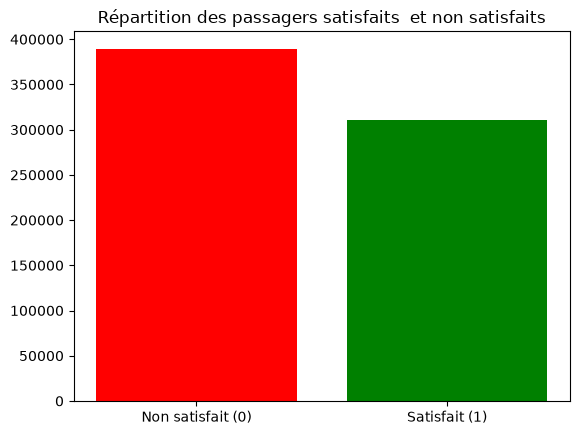

In [7]:
train["satisfaction"] = train["satisfaction"].astype(int)
print(train["satisfaction"].value_counts())
print(train["satisfaction"].value_counts(normalize=True).round(3))

effectifs = train["satisfaction"].value_counts().sort_index()
plt.bar(["Non satisfait (0)", "Satisfait (1)"], effectifs.values, color=["red", "green"])
plt.title("Répartition des passagers satisfaits  et non satisfaits")
plt.show()

## 4. Traitement des valeurs manquantes
On regarde d'abord le lien entre le retard au départ et le retard à l'arrivée.

In [8]:
# Calculer la corrélation entre les deux variables : 
print(train[["Departure Delay in Minutes", "Arrival Delay in Minutes"]].corr())


                            Departure Delay in Minutes  \
Departure Delay in Minutes                    1.000000   
Arrival Delay in Minutes                      0.842034   

                            Arrival Delay in Minutes  
Departure Delay in Minutes                  0.842034  
Arrival Delay in Minutes                    1.000000  


La corrélation obtenue entre les deux retards est de 0,843, ce qui indique une forte corrélation positive. Ainsi, les vols ayant un retard au départ ont généralement tendance à présenter également un retard à l'arrivée, ce qui rend le remplacement des valeurs manquantes plus pertinent.

In [9]:
for df in (train, test):
    df["Arrival Delay in Minutes"] = df["Arrival Delay in Minutes"].fillna(df["Departure Delay in Minutes"])

# Vérifications
print("Manquantes train:", train["Arrival Delay in Minutes"].isna().sum())
print("Manquantes test :", test["Arrival Delay in Minutes"].isna().sum())

Manquantes train: 0
Manquantes test : 0


In [10]:
# Convertir les colonnes string en "Categorie" pour Test et Train

cat_cols=["Gender", "Customer Type", "Type of Travel", "Class"]

for col in cat_cols:
    train[col]=train[col].astype("category")
    test[col]=test[col].astype("category")

#verification : 
print(train[cat_cols].dtypes)
print(test[cat_cols].dtypes)

Gender            category
Customer Type     category
Type of Travel    category
Class             category
dtype: object
Gender            category
Customer Type     category
Type of Travel    category
Class             category
dtype: object


## 5. Analyse de la corrélation entre les variables et la satisfaction


In [11]:
num_cols = train.select_dtypes(include="number").columns.drop("id")
corr = train[num_cols].corrwith(train["satisfaction"].astype(int)).sort_values(ascending=False)
print(corr.round(3))

satisfaction                         1.000
Online boarding                      0.560
Inflight entertainment               0.431
Seat comfort                         0.401
Flight Distance                      0.370
On-board service                     0.347
Cleanliness                          0.339
Leg room service                     0.330
Inflight wifi service                0.291
Baggage handling                     0.258
Checkin service                      0.250
Food and drink                       0.218
Age                                  0.203
Ease of Online booking               0.191
Gate location                        0.023
Departure Delay in Minutes          -0.036
Departure/Arrival time convenient   -0.049
Arrival Delay in Minutes            -0.051
dtype: float64


## 6. Les variables numériques selon la satisfaction
### Âge et distance de vol 

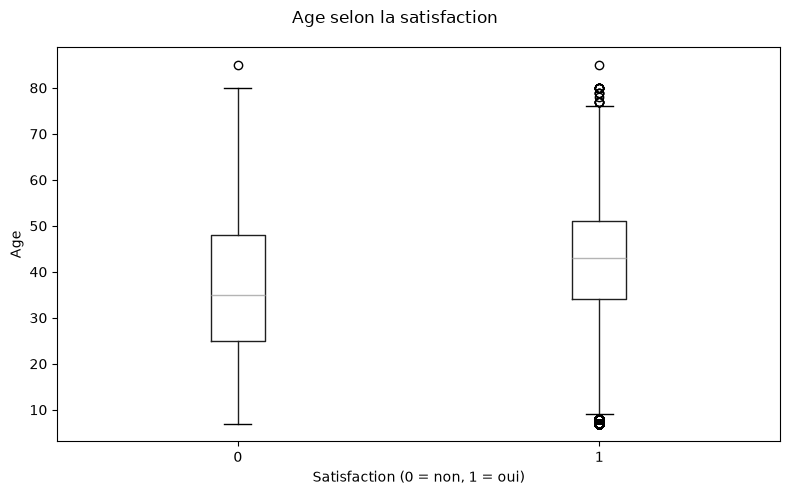

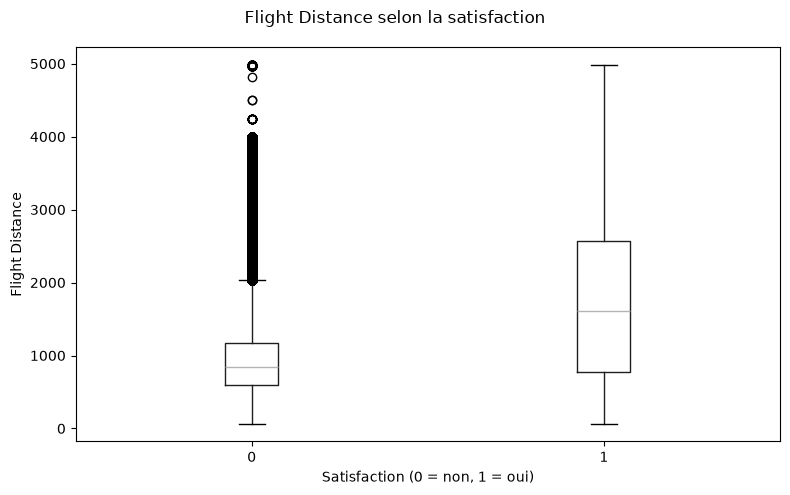

In [12]:
for col in ["Age", "Flight Distance"]:
    train.boxplot(column=col, by="satisfaction", grid=False, figsize=(8, 5))
    plt.title("")
    plt.suptitle(f"{col} selon la satisfaction")
    plt.xlabel("Satisfaction (0 = non, 1 = oui)")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

L'âge médian est plus élevé chez les passagers satisfaits que chez les non-satisfaits, ce qui suggère une relation entre l'âge et la satisfaction. De même, les passagers satisfaits ont tendance à parcourir des distances de vol plus importantes, tandis que les non-satisfaits sont davantage concentrés sur les vols de courte distance.

## 7.Les variables qualitatives selon la satisfaction

Gender      Male  Female
effectif  351683  347952 



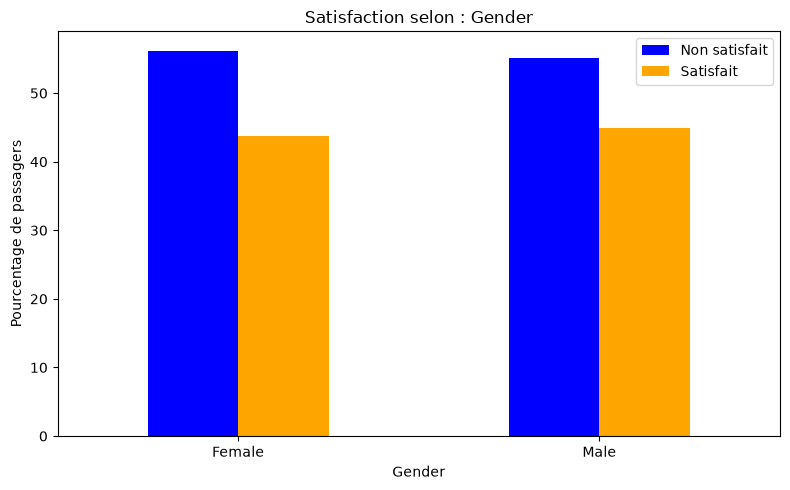

Customer Type  Loyal Customer  disloyal Customer
effectif               576990             122645 



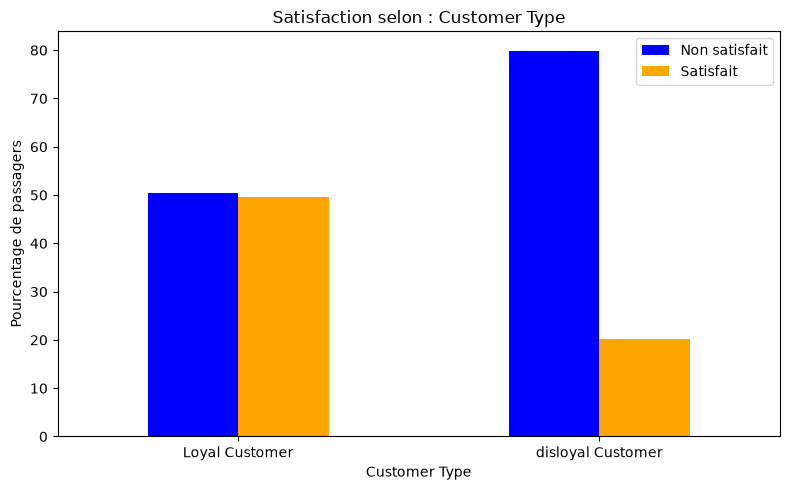

Type of Travel  Business travel  Personal Travel
effectif                 497441           202194 



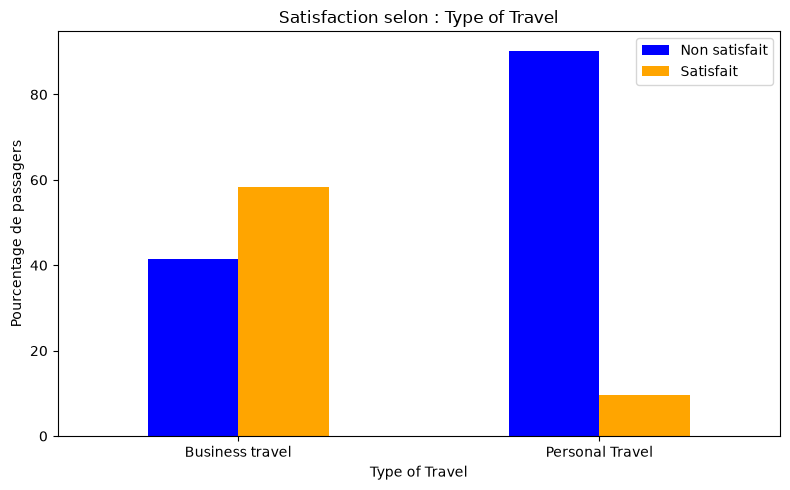

Class     Business     Eco  Eco Plus
effectif    342212  327404     30019 



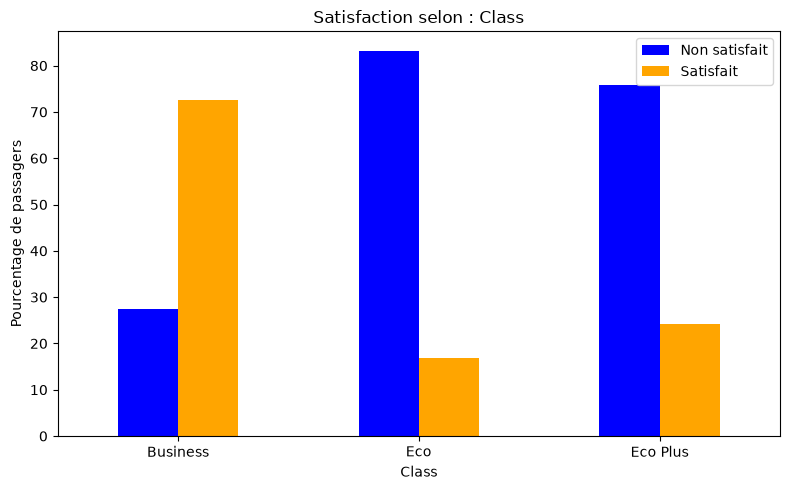

In [13]:
for col in cat_cols:
    tableau = pd.crosstab(train[col], train["satisfaction"], normalize="index") * 100
    tableau.columns = ["Non satisfait", "Satisfait"]
    print(train[col].value_counts().to_frame("effectif").T, "\n")

    tableau.plot(kind="bar", figsize=(8, 5), color=["blue", "orange"])
    plt.title(f"Satisfaction selon : {col}")
    plt.xlabel(col)
    plt.ylabel("Pourcentage de passagers")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

_La satisfaction est presque identique chez les hommes et les femmes.

_Les clients fidèles présentent une satisfaction plus équilibrée, contrairement aux clients non fidèles, majoritairement insatisfaits.

_Les voyages professionnels sont davantage associés à la satisfaction que les voyages personnels.

_La classe Business présente le niveau de satisfaction le plus élevé, contrairement aux classes Eco et Eco Plus.

## 8. Les notes données par les passagers

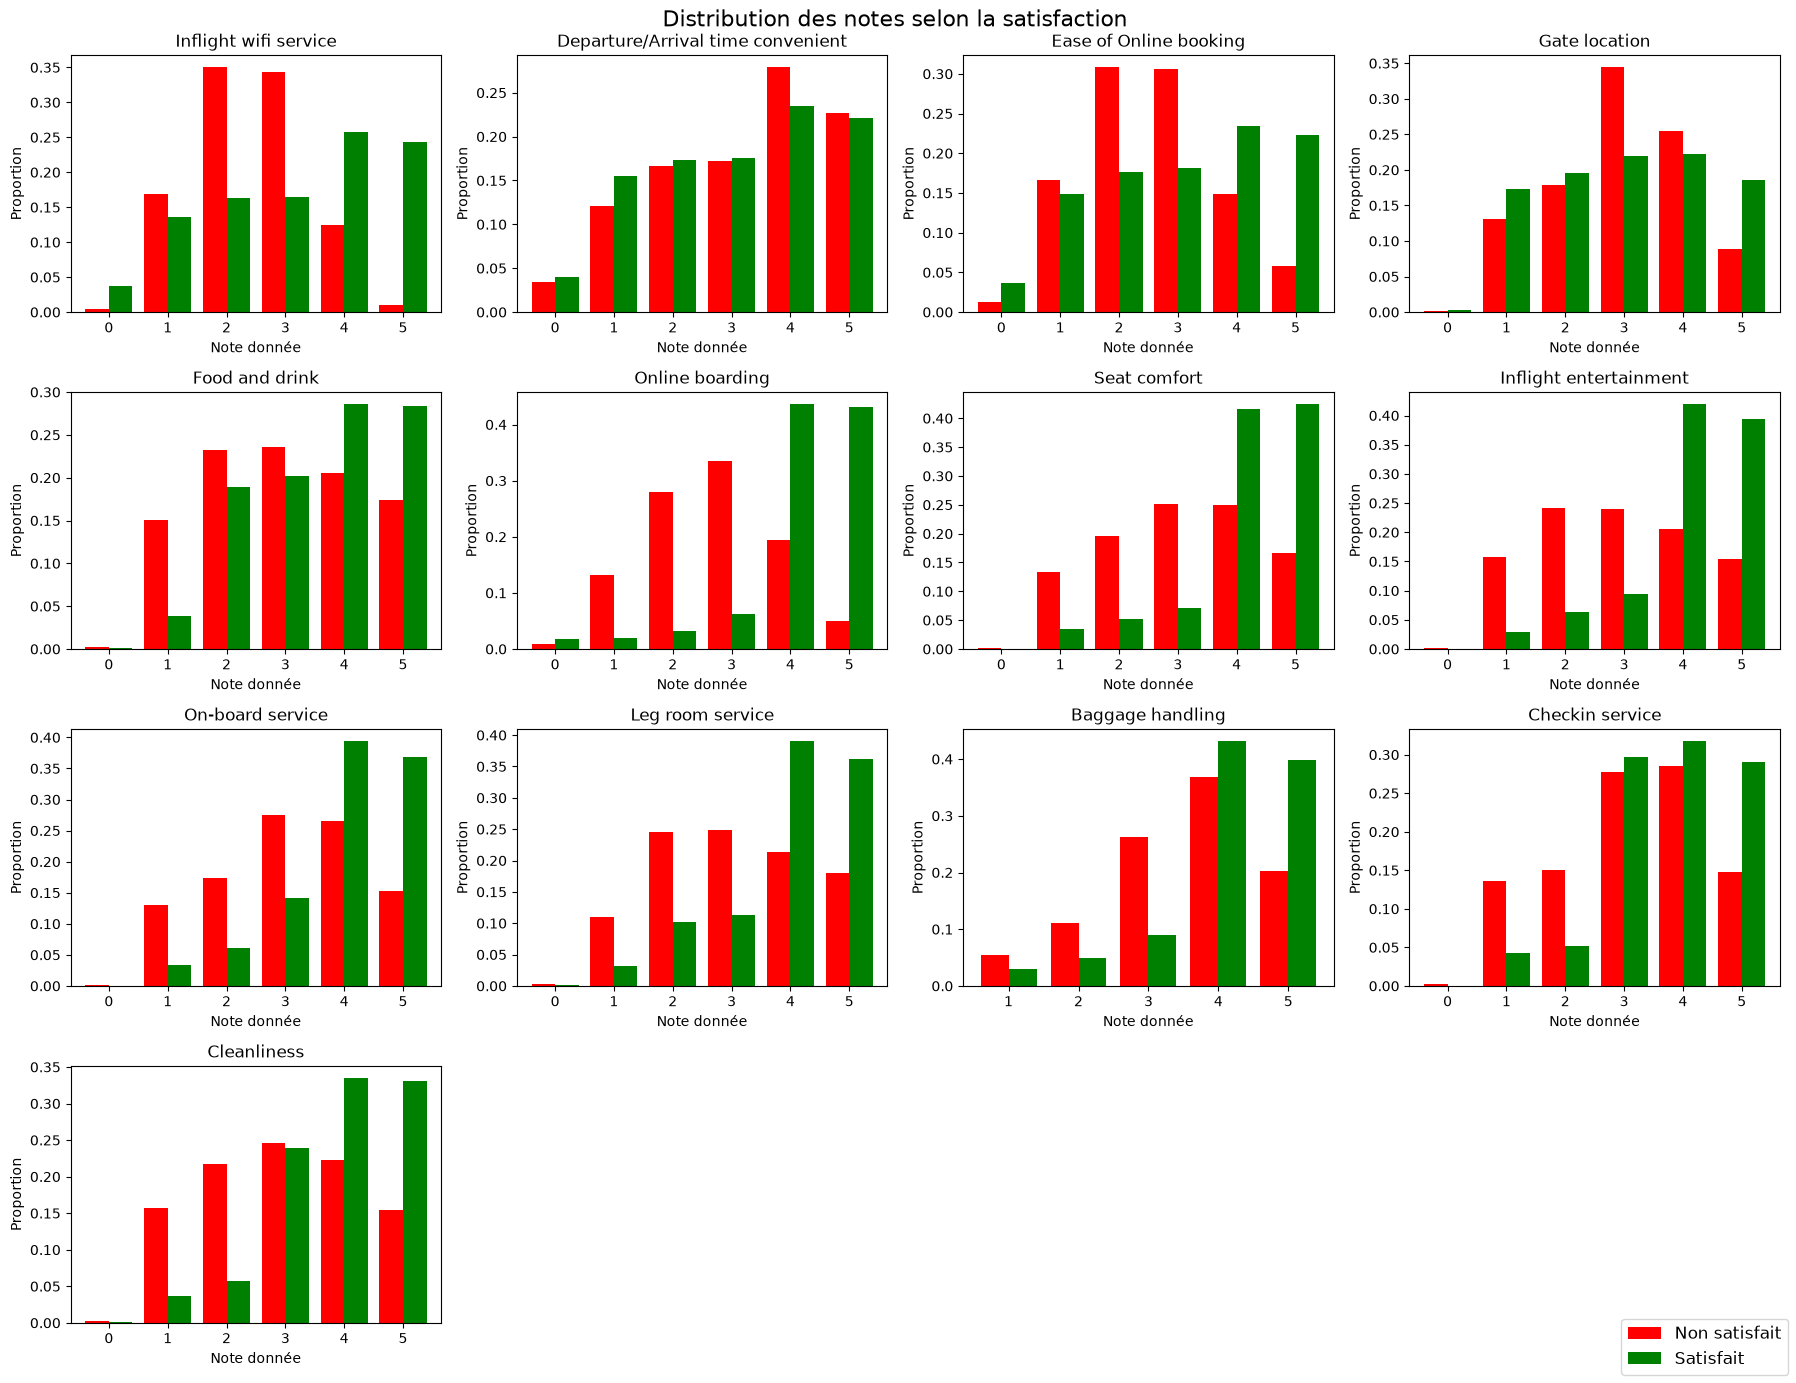

In [14]:
# Distribution des notes selon la satisfaction (proportion dans chaque groupe)
notes = ["Inflight wifi service", "Departure/Arrival time convenient", "Ease of Online booking",
         "Gate location", "Food and drink", "Online boarding", "Seat comfort",
         "Inflight entertainment", "On-board service", "Leg room service",
         "Baggage handling", "Checkin service", "Cleanliness"]
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()

for ax, col in zip(axes, notes):
    distribution = pd.crosstab(train[col], train["satisfaction"], normalize="columns")
    distribution.plot.bar(ax=ax, color=["red", "green"], legend=False, width=0.8)
    ax.set_title(col)
    ax.set_xlabel("Note donnée")
    ax.set_ylabel("Proportion")
    ax.tick_params(axis="x", rotation=0)

for ax in axes[len(notes):]:
    ax.axis("off")

fig.legend(["Non satisfait", "Satisfait"], loc="lower right", fontsize=12)
fig.suptitle("Distribution des notes selon la satisfaction", fontsize=16)
plt.tight_layout()
plt.show()

Les passagers satisfaits attribuent globalement de meilleures notes aux services à bord, notamment au confort des sièges, au Wi-Fi et au divertissement. À l’inverse, les passagers insatisfaits donnent plus souvent des notes faibles, ce qui souligne l’importance de la qualité des services dans la satisfaction globale.

## 9. Bilan de l'exploration des données
L'exploration des données a permis de mettre en évidence plusieurs caractéristiques du comportement des passagers et de leur niveau de satisfaction.
Les résultats montrent que certains facteurs, comme le type de voyage, la classe du vol et le type de client, présentent des différences selon le niveau de satisfaction. L'âge et la distance parcourue apportent également des informations intéressantes.

Ces premiers constats serviront de point de départ pour la prochaine étape du projet, qui consistera à entraîner et comparer plusieurs modèles afin de prédire la satisfaction des passagers.

# II _ Entraînement et évaluation des modèles de classification :

## 1. Modèle LightGBM : 

Training until validation scores don't improve for 100 rounds
[200]	valid_0's auc: 0.956682	valid_0's binary_logloss: 0.233121
[400]	valid_0's auc: 0.957196	valid_0's binary_logloss: 0.231734
[600]	valid_0's auc: 0.957307	valid_0's binary_logloss: 0.23133
[800]	valid_0's auc: 0.957358	valid_0's binary_logloss: 0.231121
[1000]	valid_0's auc: 0.957442	valid_0's binary_logloss: 0.230941
Early stopping, best iteration is:
[1036]	valid_0's auc: 0.957444	valid_0's binary_logloss: 0.230946
L'AUC du modèle LightGBM est : 0.9574
L'accuracy du modèle LightGBM est: 0.9245320774403796
Classification report: 
               precision    recall  f1-score   support

           0       0.92      0.94      0.93     77859
           1       0.93      0.90      0.91     62068

    accuracy                           0.92    139927
   macro avg       0.92      0.92      0.92    139927
weighted avg       0.92      0.92      0.92    139927



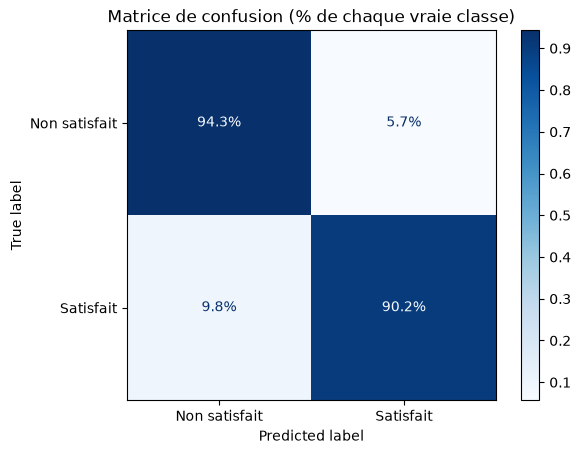

In [15]:

# Preparer les donnees : 
X=train.drop(columns=["satisfaction","id"])
Y=train["satisfaction"].astype(int)

#Séparer en entrainement et en validation : 
X_train,X_valid,Y_train ,Y_valid=train_test_split(X,Y,test_size=0.2,random_state=42,stratify=Y)

#Creer le modele : 
model_lgbm=lgb.LGBMClassifier(
    n_estimators=2000,
    learning_rate=0.05, # compromis entre vitesse et précison pour un aprentissage progressif 
    random_state=42, # pour la repoductibilité
    verbose=-1,) # pour reduire les messages d 'informations 

 
# Entrainer le model : 
model_lgbm.fit(
    X_train ,Y_train,
    eval_set=[(X_valid,Y_valid)],
    eval_metric="auc",
    callbacks=[lgb.early_stopping(100),lgb.log_evaluation(200)])



# Les deux types de prédictions
proba_lgbm = model_lgbm.predict_proba(X_valid)[:, 1]  
pred_lgbm = (proba_lgbm > 0.5).astype(int)           

# Les mesures
auc_lgbm = roc_auc_score(Y_valid, proba_lgbm)         
accuracy_lgbm = accuracy_score(Y_valid, pred_lgbm)


print("L'AUC du modèle LightGBM est :", round(auc_lgbm, 4))

print("L'accuracy du modèle LightGBM est:",accuracy_lgbm)
print("Classification report: \n",classification_report(Y_valid,pred_lgbm))


# Afficher la matrice de confusion en pourcentage
cm_pct = confusion_matrix(Y_valid, pred_lgbm, normalize="true")

ConfusionMatrixDisplay(
    cm_pct,
    display_labels=["Non satisfait", "Satisfait"]
).plot(cmap="Blues", values_format=".1%")

plt.title("Matrice de confusion (% de chaque vraie classe)")
plt.show()

La matrice de confusion montre que le modèle classe correctement 94,3 % des passagers non satisfaits et 90,2 % des passagers satisfaits. Il se trompe un peu plus sur les passagers satisfaits (9,8 % classés à tort comme non satisfaits). Les erreurs restent faibles et équilibrées entre les deux classes.

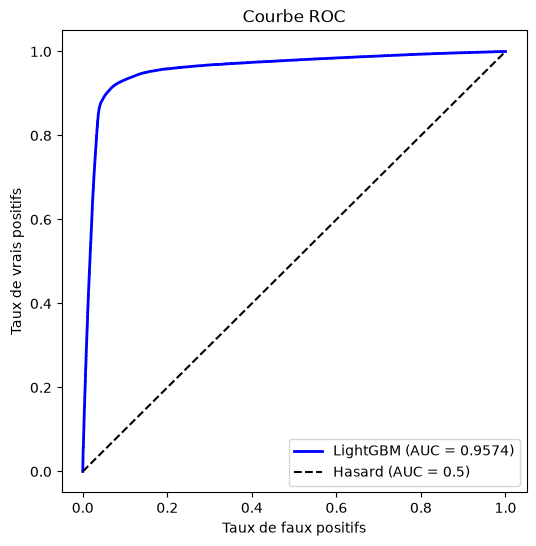

In [16]:
# Courbe ROC
fpr, tpr, seuils = roc_curve(Y_valid, proba_lgbm)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color="blue", linewidth=2, label=f"LightGBM (AUC = {auc_lgbm:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Hasard (AUC = 0.5)")
plt.xlabel("Taux de faux positifs")
plt.ylabel("Taux de vrais positifs")
plt.title("Courbe ROC")
plt.legend(loc="lower right")
plt.show()

La courbe ROC de LightGBM est proche du coin supérieur gauche, loin de la diagonale du hasard. Avec une AUC de 0,9574, le modèle sépare très bien les passagers satisfaits des insatisfaits.

## 2. La regression logistique  : 

In [17]:
# on separe les donnes numeriques et categorielles car il se traite pas de la meme façon
num_cols_model=[c for c in X.columns if c not in cat_cols]

donnees=make_column_transformer((OneHotEncoder(handle_unknown="ignore"),cat_cols),
                             (StandardScaler(),num_cols_model),)


model_rl=make_pipeline(donnees,LogisticRegression(max_iter=200,random_state=42))
model_rl.fit(X_train,Y_train)


# Les deux types de prédictions
proba_rl = model_rl.predict_proba(X_valid)[:, 1]   
pred_rl = (proba_rl > 0.5).astype(int)             

# Les mesures
auc_rl = roc_auc_score(Y_valid, proba_rl)         
accuracy_rl = accuracy_score(Y_valid, pred_rl)     



print("L'AUC de la régression logistique est :", round(auc_rl, 4))
print("L'accuracy du modèle avec la regression logistique  est:",accuracy_rl)
print("Classification report: \n",classification_report(Y_valid,pred_rl))


L'AUC de la régression logistique est : 0.9205
L'accuracy du modèle avec la regression logistique  est: 0.8780864307817647
Classification report: 
               precision    recall  f1-score   support

           0       0.88      0.90      0.89     77859
           1       0.87      0.85      0.86     62068

    accuracy                           0.88    139927
   macro avg       0.88      0.87      0.88    139927
weighted avg       0.88      0.88      0.88    139927



## 3.Modéle  Cat Boost :  

In [18]:

model_cb=CatBoostClassifier(iterations=2000,random_seed=42,verbose=False,  early_stopping_rounds=100,learning_rate=0.05)
model_cb.fit(
    X_train, Y_train,
    cat_features=cat_cols,
    eval_set=(X_valid, Y_valid)) 

proba_cb = model_cb.predict_proba(X_valid)[:, 1]   
pred_cb = (proba_cb > 0.5).astype(int)             

auc_cb = roc_auc_score(Y_valid, proba_cb)
accuracy_cb = accuracy_score(Y_valid, pred_cb)

print("L'AUC du modèle CatBoost est :", round(auc_cb, 4))
print("L'accuracy du modèle Cat Boost  est:",accuracy_cb)
print("classification report :\n",classification_report(Y_valid,pred_cb))

L'AUC du modèle CatBoost est : 0.9576
L'accuracy du modèle Cat Boost  est: 0.9249537258713472
classification report :
               precision    recall  f1-score   support

           0       0.92      0.94      0.93     77859
           1       0.93      0.90      0.91     62068

    accuracy                           0.92    139927
   macro avg       0.93      0.92      0.92    139927
weighted avg       0.92      0.92      0.92    139927



## 4. XGBoost:

In [19]:
model_xgb=XGBClassifier(n_estimators=2000,random_state=42,n_jobs=-1 ,enable_categorical=True,
    tree_method="hist",  eval_metric="auc",early_stopping_rounds=100 )

model_xgb.fit(X_train,Y_train ,eval_set=[(X_valid, Y_valid)],verbose=False)

proba_xgb = model_xgb.predict_proba(X_valid)[:, 1]   
pred_xgb = (proba_xgb > 0.5).astype(int)             


auc_xgb = roc_auc_score(Y_valid, proba_xgb)
accuracy_xgb = accuracy_score(Y_valid, pred_xgb)

print("L'AUC du modèle XGBoost est :", round(auc_xgb, 4))
print("L'accuracy du modèle XGBoost est: ",round(accuracy_xgb, 4))
print("Classification report: \n",classification_report(Y_valid,pred_xgb))

L'AUC du modèle XGBoost est : 0.9569
L'accuracy du modèle XGBoost est:  0.9242
Classification report: 
               precision    recall  f1-score   support

           0       0.92      0.94      0.93     77859
           1       0.93      0.90      0.91     62068

    accuracy                           0.92    139927
   macro avg       0.92      0.92      0.92    139927
weighted avg       0.92      0.92      0.92    139927



## 5. Reseau de neurones (MLP):

In [20]:

model_mlp = make_pipeline(
    donnees,
    MLPClassifier(
        hidden_layer_sizes=(100, 50),
        activation="relu",
        solver="adam",
        max_iter=200,
        random_state=42,
        early_stopping=True
    )
)

model_mlp.fit(X_train, Y_train)

# Les deux types de prédictions
proba_mlp = model_mlp.predict_proba(X_valid)[:, 1]   
pred_mlp = (proba_mlp > 0.5).astype(int)             
# Les mesures
auc_mlp = roc_auc_score(Y_valid, proba_mlp)
accuracy_mlp = accuracy_score(Y_valid, pred_mlp)


print("L'AUC du modèle MLP est :", round(auc_mlp, 4))
print("L'accuracy du modèle MLP est :", round(accuracy_mlp, 4))
print("Classification report :\n", classification_report(Y_valid, pred_mlp))


L'AUC du modèle MLP est : 0.9561
L'accuracy du modèle MLP est : 0.9236
Classification report :
               precision    recall  f1-score   support

           0       0.92      0.94      0.93     77859
           1       0.93      0.90      0.91     62068

    accuracy                           0.92    139927
   macro avg       0.92      0.92      0.92    139927
weighted avg       0.92      0.92      0.92    139927



## 6. Random Forest :

In [21]:

model_rf = make_pipeline(
    donnees,
    RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        random_state=42,
        n_jobs=-1
    )
)

# Entraîner le modèle
model_rf.fit(X_train, Y_train)


# Les deux types de prédictions
proba_rf = model_rf.predict_proba(X_valid)[:, 1]   
pred_rf = (proba_rf > 0.5).astype(int)             

# Les mesures
auc_rf = roc_auc_score(Y_valid, proba_rf)
accuracy_rf = accuracy_score(Y_valid, pred_rf)


print("L'AUC du modèle Random Forest est :", round(auc_rf, 4))
print("L'accuracy du modèle Random Forest est :", round(accuracy_rf, 4))
print("Classification report :\n", classification_report(Y_valid, pred_rf))

L'AUC du modèle Random Forest est : 0.9536
L'accuracy du modèle Random Forest est : 0.924
Classification report :
               precision    recall  f1-score   support

           0       0.92      0.94      0.93     77859
           1       0.93      0.90      0.91     62068

    accuracy                           0.92    139927
   macro avg       0.92      0.92      0.92    139927
weighted avg       0.92      0.92      0.92    139927



## 7. Comparaison des modèles

In [22]:
resultats = pd.DataFrame({
    "Modèle": [
        "Régression logistique",
        "LightGBM",
        "XGBoost",
        "CatBoost",
        "MLP",
        "Random Forest"
    ],
    "AUC": [
        auc_rl,
        auc_lgbm,
        auc_xgb,
        auc_cb,
        auc_mlp,
        auc_rf
    ],
    "Accuracy": [
        accuracy_rl,
        accuracy_lgbm,
        accuracy_xgb,
        accuracy_cb,
        accuracy_mlp,
        accuracy_rf
    ]
}).sort_values("AUC", ascending=False)

display(resultats.style.format({
    "AUC": "{:.4f}",
    "Accuracy": "{:.4%}"
}))


,Modèle,AUC,Accuracy
3,CatBoost,0.9576,92.4954%
1,LightGBM,0.9574,92.4532%
2,XGBoost,0.9569,92.4168%
4,MLP,0.9561,92.3632%
5,Random Forest,0.9536,92.3996%
0,Régression logistique,0.9205,87.8086%


Les résultats montrent que CatBoost obtient les meilleures performances, avec une AUC de 0,9576 et une accuracy de 92,50 %. LightGBM et XGBoost présentent des résultats très proches, suivis du MLP et du Random Forest. La régression logistique affiche des performances plus faibles, avec une accuracy de 87,81 %. Ces résultats montrent que les modèles plus complexes, notamment les méthodes de boosting, sont particulièrement adaptés à la prédiction de la satisfaction des passagers.

Au vu de ces résultats, CatBoost, LightGBM et XGBoost seront conservés pour une comparaison plus approfondie.




## 8 .La validation croisée sur les 3 meilleurs modèles (CatBoost, LightGBM, XGBoost)

Pli 1 | LightGBM | AUC = 0.9587
Pli 1 | XGBoost | AUC = 0.9581
Pli 1 | CatBoost | AUC = 0.9586
Pli 2 | LightGBM | AUC = 0.9572
Pli 2 | XGBoost | AUC = 0.957
Pli 2 | CatBoost | AUC = 0.9575
Pli 3 | LightGBM | AUC = 0.9591
Pli 3 | XGBoost | AUC = 0.9589
Pli 3 | CatBoost | AUC = 0.9594
Pli 4 | LightGBM | AUC = 0.9586
Pli 4 | XGBoost | AUC = 0.9583
Pli 4 | CatBoost | AUC = 0.9586
Pli 5 | LightGBM | AUC = 0.9588
Pli 5 | XGBoost | AUC = 0.9584
Pli 5 | CatBoost | AUC = 0.9589

        LightGBM  XGBoost  CatBoost  Moyenne des 3
Pli 1    0.9587   0.9581    0.9586         0.9590
Pli 2    0.9572   0.9570    0.9575         0.9577
Pli 3    0.9591   0.9589    0.9594         0.9596
Pli 4    0.9586   0.9583    0.9586         0.9589
Pli 5    0.9588   0.9584    0.9589         0.9591

                AUC moyenne  Écart-type
LightGBM           0.95848     0.00075
XGBoost            0.95812     0.00070
CatBoost           0.95861     0.00073
Moyenne des 3      0.95887     0.00073


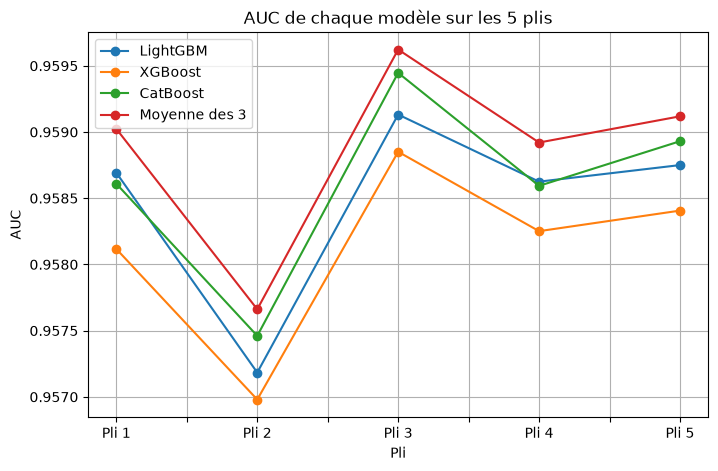

In [23]:
# 1) Les 3 modèles (nombre d'arbres trouvé par l'early stopping)
p = model_cb.get_params()
p.update(iterations=model_cb.get_best_iteration() + 1,
         learning_rate=model_cb.get_all_params()["learning_rate"], verbose=False)
p.pop("early_stopping_rounds", None)

modeles = {
    "LightGBM": clone(model_lgbm).set_params(n_estimators=model_lgbm.best_iteration_),
    "XGBoost": clone(model_xgb).set_params(n_estimators=model_xgb.best_iteration + 1, early_stopping_rounds=None),
    "CatBoost": CatBoostClassifier(**p),
}

# 2) Validation croisée à 5 plis
plis = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X, Y))
auc = {"LightGBM": [], "XGBoost": [], "CatBoost": [], "Moyenne des 3": []}

for i, (train_idx, test_idx) in enumerate(plis, start=1):
    X_tr, Y_tr = X.iloc[train_idx], Y.iloc[train_idx]
    X_te, Y_te = X.iloc[test_idx], Y.iloc[test_idx]
    proba = {}

    for nom, m in modeles.items():
        if nom == "CatBoost":
            m.fit(X_tr, Y_tr, cat_features=cat_cols)
        else:
            m.fit(X_tr, Y_tr)
        proba[nom] = m.predict_proba(X_te)[:, 1]
        auc[nom].append(roc_auc_score(Y_te, proba[nom]))
        print("Pli", i, "|", nom, "| AUC =", round(auc[nom][-1], 4))

    moyenne = np.mean(list(proba.values()), axis=0)
    auc["Moyenne des 3"].append(roc_auc_score(Y_te, moyenne))

# 3) Tableau des résultats
tableau = pd.DataFrame(auc, index=[f"Pli {i}" for i in range(1, 6)])
print("\n", tableau.round(4))
print("\n", pd.DataFrame({"AUC moyenne": tableau.mean(), "Écart-type": tableau.std()}).round(5))

# 4) Graphique
tableau.plot(marker="o", figsize=(8, 5), title="AUC de chaque modèle sur les 5 plis",
             xlabel="Pli", ylabel="AUC", grid=True)
plt.show()

La validation croisée à 5 plis montre que CatBoost,
LightGBM et XGBoost ont des performances quasi identiques 
(AUC moyenne d’environ 0,958), la moyenne des trois modèles (0,9589) étant meilleure 
que chacun d’eux pris séparément dans les 5 plis.

  ## 9 . Blending et stacking des 3 meilleurs modèles + Soumissions : 

In [24]:

# 1) Préparer le test (mêmes colonnes que l'entraînement)
X_test = test.drop(columns=["id"])[X.columns]

# 2) Probabilités des 3 modèles
noms = ["LightGBM", "XGBoost", "CatBoost"]
modeles = [model_lgbm, model_xgb, model_cb]

valid = np.column_stack([m.predict_proba(X_valid)[:, 1] for m in modeles])
tst = np.column_stack([m.predict_proba(X_test)[:, 1] for m in modeles])

# 3) Blending : moyenne des 3
blend_valid = valid.mean(axis=1)
blend_test = tst.mean(axis=1)

# 4) Stacking : une régression logistique apprend à combiner les 3
meta = LogisticRegression(max_iter=1000)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
stack_valid = cross_val_predict(meta, valid, Y_valid, cv=cv, method="predict_proba")[:, 1]

meta.fit(valid, Y_valid)
stack_test = meta.predict_proba(tst)[:, 1]

# 5) Scores de comparaison
resultats = {nom: valid[:, i] for i, nom in enumerate(noms)}
resultats["Blending"] = blend_valid
resultats["Stacking"] = stack_valid

tableau_final = pd.DataFrame({
    "AUC": {n: roc_auc_score(Y_valid, p) for n, p in resultats.items()},
    "Accuracy": {n: accuracy_score(Y_valid, p > 0.5) for n, p in resultats.items()},
}).sort_values("AUC", ascending=False)

display(tableau_final.style.format({"AUC": "{:.4f}", "Accuracy": "{:.2%}"}))

# 6) Fichiers de soumission
sub_blending = pd.DataFrame({"id": test["id"], "satisfaction": blend_test})
sub_stacking = pd.DataFrame({"id": test["id"], "satisfaction": stack_test})

sub_blending.to_csv("submission_blending.csv", index=False)
sub_stacking.to_csv("submission_stacking.csv", index=False)

print("Blending :", sub_blending.shape)
display(sub_blending.head())
print("Stacking :", sub_stacking.shape)
display(sub_stacking.head())

,AUC,Accuracy
Stacking,0.9578,92.49%
Blending,0.9578,92.47%
CatBoost,0.9576,92.50%
LightGBM,0.9574,92.45%
XGBoost,0.9569,92.42%


Blending : (299844, 2)


,id,satisfaction
0,699635,0.230912
1,699636,0.907340
2,699637,0.895799
3,699638,0.067659
4,699639,0.050347


Stacking : (299844, 2)


,id,satisfaction
0,699635,0.155513
1,699636,0.933348
2,699637,0.928172
3,699638,0.057254
4,699639,0.051001


Le blending (moyenne des probabilités de LightGBM, XGBoost et CatBoost) obtient une AUC de 0,9578 sur la validation, contre 0,9576 pour le meilleur modèle seul (CatBoost). Le stacking donne le même score, sans apport supplémentaire.

**Résultats des soumissions sur Kaggle :**
- Stacking : 0,95832 (public) et 0,95916 (privé).
- Blending : 0,95831 (public) et 0,95915 (privé).

L'écart entre le stacking et le blending est de 0,00001, ce qui est négligeable. Nous retenons donc le **blending**, plus simple et tout aussi performant.

L'écart d'environ 0,0008 entre le classement public et le classement privé reste faible : les deux méthodes donnent des résultats stables d'un échantillon de test à l'autre.


## 10. Modèle final : feature engineering, LightGBM + CatBoost et soumission finale

In [27]:
N_SPLITS, SEED = 5, 42

# classe_voyage est créée dans prep(), donc on l'ajoute à cat_cols
cats = cat_cols + ["classe_voyage"]

def prep(df):
    df = df.drop(columns=["id", "satisfaction"], errors="ignore").copy()
    dep, arr = "Departure Delay in Minutes", "Arrival Delay in Minutes"
    df[arr] = df[arr].fillna(df[dep])
    df["note_mean"] = df[notes].mean(axis=1)
    df["note_min"] = df[notes].min(axis=1)
    df["note_std"] = df[notes].std(axis=1)
    df["notes_basses"] = (df[notes] <= 2).sum(axis=1)
    df["delay_sum"] = df[dep] + df[arr]
    df["classe_voyage"] = df["Class"].astype(str) + "_" + df["Type of Travel"].astype(str)
    return df

y = train["satisfaction"].astype(int).values
X, X_test = prep(train), prep(test)

for c in cats:
    X[c] = X[c].astype("category")
    X_test[c] = pd.Categorical(X_test[c], categories=X[c].cat.categories)

oof = {"lgb": np.zeros(len(X)), "cb": np.zeros(len(X))}
pred_test = {"lgb": np.zeros(len(X_test)), "cb": np.zeros(len(X_test))}

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
for fold, (tr, va) in enumerate(skf.split(X, y), 1):
    X_tr, X_va, y_tr, y_va = X.iloc[tr], X.iloc[va], y[tr], y[va]

    models = {
        "lgb": lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.03, subsample=0.8,
                                  subsample_freq=1, colsample_bytree=0.7,
                                  verbose=-1, random_state=SEED),
        "cb": CatBoostClassifier(iterations=2000, learning_rate=0.06, eval_metric="AUC",
                                 verbose=False, random_seed=SEED,
                                 early_stopping_rounds=200, cat_features=cats),
    }

    
    models["lgb"].fit(X_tr, y_tr, eval_set=[(X_va, y_va)], eval_metric="auc",
                      callbacks=[lgb.early_stopping(200, verbose=False)])
    
    models["cb"].fit(X_tr, y_tr, eval_set=(X_va, y_va))

    for name, m in models.items():
        oof[name][va] = m.predict_proba(X_va)[:, 1]
        pred_test[name] += m.predict_proba(X_test)[:, 1] / N_SPLITS

    print(f"fold {fold} | LGB {roc_auc_score(y_va, oof['lgb'][va]):.5f} "
          f"| CB {roc_auc_score(y_va, oof['cb'][va]):.5f}")

print("=" * 40)
print("AUC OOF LightGBM :", round(roc_auc_score(y, oof["lgb"]), 5))
print("AUC OOF CatBoost :", round(roc_auc_score(y, oof["cb"]), 5))
print("AUC OOF Moyenne  :", round(roc_auc_score(y, (oof["lgb"] + oof["cb"]) / 2), 5))

pred = (pred_test["lgb"] + pred_test["cb"]) / 2



fold 1 | LGB 0.95892 | CB 0.95866
fold 2 | LGB 0.95759 | CB 0.95731
fold 3 | LGB 0.95928 | CB 0.95944
fold 4 | LGB 0.95866 | CB 0.95843
fold 5 | LGB 0.95913 | CB 0.95894
AUC OOF LightGBM : 0.95871
AUC OOF CatBoost : 0.95855
AUC OOF Moyenne  : 0.95884


# III. Soumission finale  :

In [28]:


submission = pd.DataFrame({"id": test["id"], "satisfaction": pred})


submission.to_csv("submission_final .csv", index=False)
print("Fichier submission_final.csv créé avec succès !")
print("Dimensions :", submission.shape)
submission.head()


Fichier submission_final.csv créé avec succès !
Dimensions : (299844, 2)


,id,satisfaction
0,699635,0.248303
1,699636,0.890184
2,699637,0.902518
3,699638,0.077840
4,699639,0.057289
